# First fitted model: weekly profile plus annual seasonality

Predict hourly end-user energy in MWh using Swiss local calendar features. Compare against the unchanged 52-week baseline on October-December 2024 (2,209 hours).

The model learns a typical value for each of the 168 local weekday/hour combinations, plus one smooth annual sine/cosine cycle. Fit ordinary least squares once, using only observations that satisfy our maturity policy before the earliest forecast issue time. Freeze the coefficients throughout evaluation; there is no tuning on these evaluation errors.

This remains a development experiment: 2024 has already been inspected. Source interval ends are assumed. Availability is approximated by the start of the following source month plus six calendar months; historical release versions remain unverified. These results are not an independent final test.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

project_dir = Path.cwd()
if not (project_dir / "src" / "preparation.py").exists():
    project_dir = project_dir.parent
assert (project_dir / "src" / "preparation.py").exists()
src_dir = str(project_dir / "src")
if src_dir not in sys.path:
    sys.path.insert(0, src_dir)
from preparation import (
    load_quarter_hour_data,
    prepare_quarter_hour_data,
    aggregate_hourly_energy,
)

## 1. Load and validate both years

Each source hour must contain four quarter-hour observations. Check continuity across the year boundary before using row shifts as elapsed-hour lags.

In [2]:
hourly_frames = []
for year in [2023, 2024]:
    raw = load_quarter_hour_data(
        project_dir / "data" / "raw" / f"EnergieUebersichtCH-{year}.xlsx"
    )
    prepared = prepare_quarter_hour_data(raw)
    frame = aggregate_hourly_energy(prepared)
    assert len(frame) == (8784 if year == 2024 else 8760)
    assert frame["interval_count"].eq(4).all()
    assert frame["end_user_energy_mwh"].notna().all()
    assert np.isclose(
        raw["end_user_energy_kwh"].sum(), frame["end_user_energy_kwh"].sum(),
        rtol=1e-12, atol=0.01,
    )
    hourly_frames.append(frame)

hourly = pd.concat(hourly_frames)
assert hourly.index.is_unique
assert hourly.index.is_monotonic_increasing
assert hourly.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all()
print(f"Prepared {len(hourly):,} complete hours across 2023 and 2024.")

Prepared 17,544 complete hours across 2023 and 2024.


## 2. Freeze the training set before the first forecast

For each hourly observation, calculate maturity from its interval end. Training includes only values mature by the first issue time. This is stricter than checking that a timestamp is merely earlier than its target.

The evaluation window and noon issue times match notebook 02. Training remains fixed, even when more observations would mature later in the quarter.

In [3]:
def assumed_maturity_utc(interval_starts):
    local_ends = (
        interval_starts + pd.Timedelta(hours=1)
    ).tz_convert("Europe/Zurich").tz_localize(None)
    maturity = (
        local_ends.to_period("M").to_timestamp()
        + pd.offsets.MonthBegin(1)
        + pd.DateOffset(months=6)
    )
    return maturity.tz_localize("Europe/Zurich").tz_convert("UTC")

start_local = pd.Timestamp("2024-10-01", tz="Europe/Zurich")
end_local = pd.Timestamp("2025-01-01", tz="Europe/Zurich")
evaluation = hourly.loc[
    (hourly["hour_start_local"] >= start_local)
    & (hourly["hour_start_local"] < end_local),
    ["end_user_energy_mwh", "hour_start_local"],
].rename(columns={"end_user_energy_mwh": "actual_mwh"}).copy()
local_dates = evaluation["hour_start_local"].dt.tz_localize(None).dt.normalize()
evaluation["issue_time_utc"] = (
    local_dates - pd.Timedelta(days=1) + pd.Timedelta(hours=12)
).dt.tz_localize("Europe/Zurich").dt.tz_convert("UTC")
assert len(evaluation) == 2209
first_issue = evaluation["issue_time_utc"].min()

maturity = assumed_maturity_utc(hourly.index)
train_mask = (maturity <= first_issue) & (hourly.index < first_issue)
training = hourly.loc[train_mask].copy()
assert len(training) > 0
assert (maturity[train_mask] <= first_issue).all()
assert training.index.intersection(evaluation.index).empty

print("First issue:", first_issue.tz_convert("Europe/Zurich"))
print("Training starts:", training["hour_start_local"].iloc[0])
print("Last training interval starts:", training["hour_start_local"].iloc[-1])
print(f"Training hours: {len(training):,}; evaluation hours: {len(evaluation):,}")

First issue: 2024-09-30 12:00:00+02:00
Training starts: 2023-01-01 00:00:00+01:00
Last training interval starts: 2024-02-29 22:00:00+01:00
Training hours: 10,199; evaluation hours: 2,209


## 3. Calendar features and least-squares fit

Use 168 indicator columns for local weekday/hour combinations (Monday 00:00 through Sunday 23:00). No extra intercept is needed: exactly one indicator is active per row. Two additional columns represent a smooth annual sine/cosine cycle, using each year's actual length.

The annual correction is shared by all weekday/hour combinations. This intentionally simple model has no weather, holiday, recent-consumption, or trend inputs. It predicts the same energy for both occurrences of a repeated local hour. All features are known before issue time.

`np.linalg.lstsq` chooses coefficients to minimize squared training errors. It requires no additional modelling package.

In [4]:
def calendar_features(local_times):
    local_times = pd.DatetimeIndex(local_times)
    hour_of_week = local_times.dayofweek * 24 + local_times.hour
    weekly_profile = np.eye(168)[hour_of_week]
    days_in_year = np.where(local_times.is_leap_year, 366, 365)
    year_fraction = (
        local_times.dayofyear - 1 + local_times.hour / 24
    ) / days_in_year
    angle = 2 * np.pi * np.asarray(year_fraction)
    return np.column_stack([
        weekly_profile, np.sin(angle), np.cos(angle),
    ])

X_train = calendar_features(training["hour_start_local"])
y_train = training["end_user_energy_mwh"].to_numpy()
coefficients, _, rank, _ = np.linalg.lstsq(X_train, y_train, rcond=None)
assert rank == X_train.shape[1]

X_eval = calendar_features(evaluation["hour_start_local"])
evaluation["calendar_model_mwh"] = X_eval @ coefficients
assert np.isfinite(evaluation["calendar_model_mwh"]).all()
print(f"Fitted {len(coefficients)} coefficients once on mature training data.")

Fitted 170 coefficients once on mature training data.


## 4. Compare with the unchanged 52-week baseline

Both methods use the same target hours. Check that the 52-week source intervals also meet the maturity policy at their respective issue times. Metrics weight each evaluated hour equally; mean error is prediction minus actual.

In [5]:
lag = pd.Timedelta(weeks=52)
evaluation["52_week_prediction_mwh"] = (
    hourly["end_user_energy_mwh"].shift(52 * 168).reindex(evaluation.index)
)
source_maturity = assumed_maturity_utc(evaluation.index - lag)
assert (source_maturity <= evaluation["issue_time_utc"]).all()
prediction_columns = ["52_week_prediction_mwh", "calendar_model_mwh"]
assert evaluation[["actual_mwh"] + prediction_columns].notna().all().all()

errors = evaluation[prediction_columns].sub(evaluation["actual_mwh"], axis=0)
scores = pd.DataFrame({
    "MAE (MWh)": errors.abs().mean(),
    "RMSE (MWh)": np.sqrt(errors.pow(2).mean()),
    "Mean error (MWh)": errors.mean(),
})
display(scores.round(2))

monthly_mae = (
    errors.abs()
    .assign(local_month=evaluation["hour_start_local"].dt.month)
    .groupby("local_month").mean()
)
display(monthly_mae.round(2))

,MAE (MWh),RMSE (MWh),Mean error (MWh)
52_week_prediction_mwh,407.67,527.38,-98.45
calendar_model_mwh,367.99,481.89,-73.35


,52_week_prediction_mwh,calendar_model_mwh
local_month,,
10,288.30,257.60
11,386.91,392.19
12,547.31,455.11


## 5. Inspect a week before drawing conclusions

Use the first complete Monday-Sunday week in the evaluation window, October 7-13, rather than selecting the model's best or worst week. Display timestamps explicitly in Swiss local time.

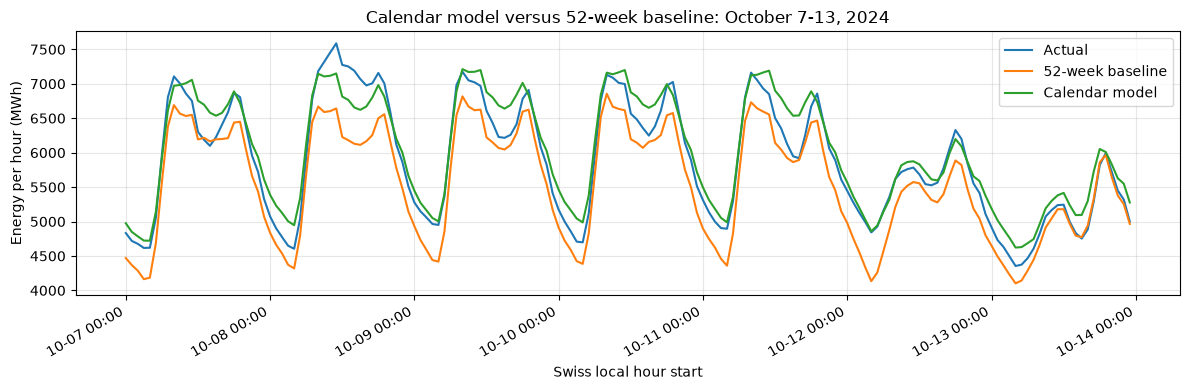

In [6]:
import matplotlib.dates as mdates
from zoneinfo import ZoneInfo
week = evaluation.loc[
    (evaluation["hour_start_local"] >= pd.Timestamp("2024-10-07", tz="Europe/Zurich"))
    & (evaluation["hour_start_local"] < pd.Timestamp("2024-10-14", tz="Europe/Zurich"))
]
fig, ax = plt.subplots(figsize=(12, 4))
for column, label in [
    ("actual_mwh", "Actual"),
    ("52_week_prediction_mwh", "52-week baseline"),
    ("calendar_model_mwh", "Calendar model"),
]:
    ax.plot(week["hour_start_local"], week[column], label=label)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d %H:%M", tz=ZoneInfo("Europe/Zurich")))
ax.set(xlabel="Swiss local hour start", ylabel="Energy per hour (MWh)",
       title="Calendar model versus 52-week baseline: October 7-13, 2024")
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## Results and next step

Fresh-kernel execution used 10,199 mature training hours, starting January 1, 2023, and ending with the interval starting February 29, 2024 at 22:00 Swiss time. The following hour ends in March and is excluded by the interval-end maturity rule. Coefficients were frozen before the first issue time, September 30, 2024 at noon Swiss time.

| Method | MAE (MWh) | RMSE (MWh) | Mean error (MWh) |
| --- | ---: | ---: | ---: |
| 52-week baseline | 407.67 | 527.38 | -98.45 |
| Calendar model | 367.99 | 481.89 | -73.35 |

The calendar model reduced MAE by approximately 9.7% and RMSE by 8.6% relative to the unchanged 52-week baseline. It remains a development candidate under the assumed maturity policy.

| Local month | 52-week MAE | Calendar-model MAE |
| --- | ---: | ---: |
| October | 288.30 | 257.60 |
| November | 386.91 | 392.19 |
| December | 547.31 | 455.11 |

The improvement came from October and December; November became slightly worse. Both methods underpredicted overall. The calendar model averages a weekly profile across mature history and adds a shared smooth annual cycle. It has no holiday or weather features. The comparison does not isolate a causal reason for the gain.

Next, inspect the displayed October 7-13 profiles and describe where the model misses level or shape before adding features. Retain the fixed training cutoff and unchanged baseline. The repeatedly inspected 2024 quarter is development data; a separate later evaluation period and verification of historical release versions are still required.


In [7]:
weekday_mae = (
    errors.abs()
    .assign(weekday=evaluation["hour_start_local"].dt.dayofweek)
    .groupby("weekday")
    .mean()
)

weekday_mae.index = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday",
]

display(weekday_mae.round(2))

,52_week_prediction_mwh,calendar_model_mwh
Monday,495.38,317.76
Tuesday,446.98,356.36
Wednesday,321.21,380.16
Thursday,377.65,430.02
Friday,496.18,425.58
Saturday,375.72,341.63
Sunday,337.80,325.44


In [8]:
daily_mae = (
    errors.abs()
    .groupby(evaluation["hour_start_local"].dt.date)
    .mean()
)

daily_mae["model_minus_baseline_mwh"] = (
    daily_mae["calendar_model_mwh"]
    - daily_mae["52_week_prediction_mwh"]
)

midweek = pd.to_datetime(daily_mae.index).dayofweek
display(
    daily_mae.loc[np.isin(midweek, [2, 3])]
    .sort_values("model_minus_baseline_mwh", ascending=False)
    .head(10)
    .round(2)
)

,52_week_prediction_mwh,calendar_model_mwh,model_minus_baseline_mwh
hour_start_local,,,
2024-12-25,251.09,1027.34,776.25
2024-12-26,319.73,740.38,420.65
2024-12-05,259.34,668.88,409.54
2024-12-04,235.40,554.91,319.51
2024-11-20,203.22,509.12,305.91
2024-11-21,719.48,1017.54,298.06
2024-12-12,610.85,806.08,195.23
2024-10-17,179.57,310.02,130.45
2024-10-16,112.09,227.74,115.65


In [9]:
daily_bias = (
    errors
    .groupby(evaluation["hour_start_local"].dt.date)
    .mean()
)

dates = [
    pd.Timestamp(date).date()
    for date in ["2024-12-04", "2024-12-05", "2024-12-25", "2024-12-26"]
]

display(daily_bias.loc[dates].round(2))

,52_week_prediction_mwh,calendar_model_mwh
hour_start_local,,
2024-12-04,235.40,-554.91
2024-12-05,259.28,-668.88
2024-12-25,-73.49,1027.34
2024-12-26,-288.34,740.38


In [10]:
def holiday_indicator(local_times):
    local_times = pd.DatetimeIndex(local_times).tz_convert("Europe/Zurich")

    return np.asarray(
        ((local_times.month == 1) & (local_times.day == 1))
        | ((local_times.month == 12) & np.isin(local_times.day, [25, 26])),
        dtype=float,
    )


holiday_train = holiday_indicator(training["hour_start_local"])

X_train_holiday = np.column_stack([X_train, holiday_train])

holiday_coefficients, _, holiday_rank, _ = np.linalg.lstsq(
    X_train_holiday,
    y_train,
    rcond=None,
)

assert holiday_rank == X_train_holiday.shape[1]

print(f"Marked training hours: {int(holiday_train.sum())}")
print(f"Holiday correction: {holiday_coefficients[-1]:+.2f} MWh")

Marked training hours: 96
Holiday correction: -1541.45 MWh


In [11]:
training_dates = training["hour_start_local"].dt.date.to_numpy()
marked_dates = sorted(set(training_dates[holiday_train.astype(bool)]))

full_correction = float(holiday_coefficients[-1])
results = []

for omitted_date in marked_dates:
    keep = training_dates != omitted_date

    # Remove all 24 hours of this holiday date.
    assert (~keep).sum() == 24
    assert (holiday_train[~keep] == 1).all()

    fitted_coefficients, _, fitted_rank, _ = np.linalg.lstsq(
        X_train_holiday[keep],
        y_train[keep],
        rcond=None,
    )
    assert fitted_rank == X_train_holiday.shape[1]

    correction = float(fitted_coefficients[-1])
    change = correction - full_correction

    results.append({
        "Omitted date": omitted_date,
        "Training hours": int(keep.sum()),
        "Holiday correction (MWh)": correction,
        "Change from full fit (MWh)": change,
        "Absolute change (%)": 100 * abs(change) / abs(full_correction),
    })

sensitivity_results = pd.DataFrame(results).set_index("Omitted date")

print(f"Original holiday correction: {full_correction:+.2f} MWh")
display(sensitivity_results.round(2))

Original holiday correction: -1541.45 MWh


,Training hours,Holiday correction (MWh),Change from full fit (MWh),Absolute change (%)
Omitted date,,,,
2023-01-01,10175,-1678.18,-136.72,8.87
2023-12-25,10175,-1432.36,109.10,7.08
2023-12-26,10175,-1529.19,12.27,0.80
2024-01-01,10175,-1529.60,11.86,0.77


In [12]:
from urllib.request import urlopen

url_2022 = (
    "https://www.swissgrid.ch/dam/"
    "jcr%3Ae3af783a-6c00-40d9-bb3e-a630fb492dfb/"
    "EnergieUebersichtCH-2022.xlsx"
)

path_2022 = project_dir / "data" / "raw" / "EnergieUebersichtCH-2022.xlsx"

if not path_2022.exists():
    with urlopen(url_2022, timeout=120) as response:
        workbook_bytes = response.read()

    assert workbook_bytes.startswith(b"PK"), "Download is not an XLSX file."
    path_2022.write_bytes(workbook_bytes)

print(f"Workbook: {path_2022.name}")
print(f"Size: {path_2022.stat().st_size / 1_000_000:.2f} MB")

# Inspect the source column descriptions and units.
display(pd.read_excel(
    path_2022,
    sheet_name="Zeitreihen0h15",
    header=None,
    nrows=2,
    usecols="A:D",
))

raw_2022 = load_quarter_hour_data(path_2022)
prepared_2022 = prepare_quarter_hour_data(raw_2022)
hourly_2022 = aggregate_hourly_energy(prepared_2022)

assert len(raw_2022) == 35040
assert len(hourly_2022) == 8760
assert hourly_2022["interval_count"].eq(4).all()
assert hourly_2022["end_user_energy_mwh"].notna().all()
assert hourly_2022.index.is_unique
assert hourly_2022.index.is_monotonic_increasing
assert hourly_2022.index.to_series().diff().dropna().eq(
    pd.Timedelta(hours=1)
).all()

assert np.isclose(
    raw_2022["end_user_energy_kwh"].sum(),
    hourly_2022["end_user_energy_kwh"].sum(),
    rtol=1e-12,
    atol=0.01,
)

# Confirm that 2022 joins the existing data without a gap.
assert hourly_2022.index[-1] + pd.Timedelta(hours=1) == hourly.index[0]

print(f"Validated hourly observations: {len(hourly_2022):,}")
print("First local hour:", hourly_2022["hour_start_local"].iloc[0])
print("Last local hour:", hourly_2022["hour_start_local"].iloc[-1])
print(
    "Annual end-user energy:",
    f"{hourly_2022['end_user_energy_mwh'].sum() / 1_000_000:.3f} TWh",
)

Workbook: EnergieUebersichtCH-2022.xlsx
Size: 24.75 MB


,0,1,2,3
0,NaN,Summe endverbrauchte Energie Regelblock Schwei...,Summe produzierte Energie Regelblock Schweiz\n...,Summe verbrauchte Energie Regelblock Schweiz\n...
1,Zeitstempel,kWh,kWh,kWh


Validated hourly observations: 8,760
First local hour: 2022-01-01 00:00:00+01:00
Last local hour: 2022-12-31 23:00:00+01:00
Annual end-user energy: 55.452 TWh


In [13]:
# Combine 2022 with the existing 2023–2024 data.
expanded_hourly = pd.concat([hourly_2022, hourly]).sort_index()

assert expanded_hourly.index.is_unique
assert expanded_hourly.index.to_series().diff().dropna().eq(
    pd.Timedelta(hours=1)
).all()

# Keep the original forecast cutoff.
expanded_maturity = assumed_maturity_utc(expanded_hourly.index)
expanded_train_mask = (
    (expanded_maturity <= first_issue)
    & (expanded_hourly.index < first_issue)
)
expanded_training = expanded_hourly.loc[expanded_train_mask].copy()

assert len(expanded_training) == len(training) + 8760
pd.testing.assert_frame_equal(
    expanded_training.loc[training.index],
    training,
)

# Use exactly the same calendar and holiday features.
expanded_holidays = holiday_indicator(
    expanded_training["hour_start_local"]
)
expanded_X = np.column_stack([
    calendar_features(expanded_training["hour_start_local"]),
    expanded_holidays,
])
expanded_y = expanded_training["end_user_energy_mwh"].to_numpy()

expanded_coefficients, _, expanded_rank, _ = np.linalg.lstsq(
    expanded_X,
    expanded_y,
    rcond=None,
)

assert expanded_rank == expanded_X.shape[1]
assert np.isfinite(expanded_coefficients).all()

# Show the holiday dates supporting the new estimate.
marked_training = expanded_training.loc[expanded_holidays.astype(bool)]
display(
    marked_training.groupby(marked_training["hour_start_local"].dt.date)
    .size()
    .rename("Training hours")
    .to_frame()
)

print(f"Expanded training hours: {len(expanded_training):,}")
print(f"Original holiday correction: {holiday_coefficients[-1]:+.2f} MWh")
print(f"Expanded holiday correction: {expanded_coefficients[-1]:+.2f} MWh")
print(
    "Change:",
    f"{expanded_coefficients[-1] - holiday_coefficients[-1]:+.2f} MWh",
)

,Training hours
hour_start_local,
2022-01-01,24
2022-12-25,24
2022-12-26,24
2023-01-01,24
2023-12-25,24
2023-12-26,24
2024-01-01,24


Expanded training hours: 18,959
Original holiday correction: -1541.45 MWh
Expanded holiday correction: -1399.38 MWh
Change: +142.07 MWh


In [14]:
# Fit a calendar-only model on the expanded training data.
expanded_calendar_X = calendar_features(
    expanded_training["hour_start_local"]
)

expanded_calendar_coefficients, _, expanded_calendar_rank, _ = (
    np.linalg.lstsq(expanded_calendar_X, expanded_y, rcond=None)
)
assert expanded_calendar_rank == expanded_calendar_X.shape[1]

# Predict the same evaluation hours without changing existing predictions.
comparison = evaluation[[
    "actual_mwh",
    "52_week_prediction_mwh",
    "calendar_model_mwh",
]].copy()

eval_calendar_X = calendar_features(evaluation["hour_start_local"])
eval_holidays = holiday_indicator(evaluation["hour_start_local"])

# Reconstruct the original holiday model for comparison.
comparison["original_holiday_model"] = (
    np.column_stack([eval_calendar_X, eval_holidays])
    @ holiday_coefficients
)

comparison["expanded_calendar_model"] = (
    eval_calendar_X @ expanded_calendar_coefficients
)

comparison["expanded_holiday_model"] = (
    np.column_stack([eval_calendar_X, eval_holidays])
    @ expanded_coefficients
)

comparison_errors = comparison.drop(columns="actual_mwh").sub(
    comparison["actual_mwh"], axis=0
)
assert np.isfinite(comparison_errors.to_numpy()).all()

comparison_scores = pd.DataFrame({
    "MAE (MWh)": comparison_errors.abs().mean(),
    "RMSE (MWh)": np.sqrt(comparison_errors.pow(2).mean()),
    "Mean error (MWh)": comparison_errors.mean(),
})

display(comparison_scores.round(2))

,MAE (MWh),RMSE (MWh),Mean error (MWh)
52_week_prediction_mwh,407.67,527.38,-98.45
calendar_model_mwh,367.99,481.89,-73.35
original_holiday_model,362.46,467.87,-75.25
expanded_calendar_model,366.64,478.15,-30.55
expanded_holiday_model,359.12,457.49,-33.27


In [15]:
print("Monthly MAE:")
display(
    comparison_errors.abs()
    .groupby(evaluation["hour_start_local"].dt.month)
    .mean()
    .round(2)
)

is_holiday = eval_holidays.astype(bool)

print("MAE on marked dates versus other dates:")
display(
    comparison_errors.abs()
    .groupby(np.where(is_holiday, "Marked dates", "Other dates"))
    .mean()
    .round(2)
)

print("Mean error on marked dates:")
display(
    comparison_errors.loc[is_holiday]
    .mean()
    .rename("Mean error (MWh)")
    .to_frame()
    .round(2)
)

Monthly MAE:


,52_week_prediction_mwh,calendar_model_mwh,original_holiday_model,expanded_calendar_model,expanded_holiday_model
hour_start_local,,,,,
10,288.30,257.60,273.32,275.05,289.51
11,386.91,392.19,385.20,382.22,377.34
12,547.31,455.11,429.73,443.29,411.19


MAE on marked dates versus other dates:


,52_week_prediction_mwh,calendar_model_mwh,original_holiday_model,expanded_calendar_model,expanded_holiday_model
Marked dates,285.41,883.86,735.03,958.10,643.63
Other dates,410.39,356.53,354.19,353.51,352.80


Mean error on marked dates:


,Mean error (MWh)
52_week_prediction_mwh,-180.92
calendar_model_mwh,883.86
original_holiday_model,-634.62
expanded_calendar_model,958.10
expanded_holiday_model,-419.60


## Development conclusion: freeze the model definitions

We used October–December 2024 to develop and compare our forecasting
methods. Because we repeatedly inspected this period and used its errors
to guide feature choices, these scores are development results.

### Overall results

| Model | MAE (MWh) | RMSE (MWh) | Mean error (MWh) |
| --- | ---: | ---: | ---: |
| 52-week baseline | 407.67 | 527.38 | -98.45 |
| Original calendar model | 367.99 | 481.89 | -73.35 |
| Original calendar + holiday | 362.46 | 467.87 | -75.25 |
| Expanded calendar model | 366.64 | 478.15 | -30.55 |
| Expanded calendar + holiday | 359.12 | 457.49 | -33.27 |

Expanded training adds 2022 while retaining the original maturity cutoff.
It contains 18,959 hours and seven marked holiday dates.

### What we learned

The expanded holiday model achieved the lowest overall MAE and RMSE.
However, its improvement was uneven: compared with the original calendar
model, October worsened while November and December improved.

With expanded training, adding the holiday feature reduced marked-date
MAE from 958.10 to 643.63 MWh. On other dates, MAE changed only slightly,
from 353.51 to 352.80 MWh.

The expanded holiday model still underpredicted on December 25–26:
its mean error was -419.60 MWh. The 52-week baseline performed better on
those dates, with MAE of 285.41 MWh.

The holiday feature is therefore a promising candidate, but its benefit
on future data has not been established.

### Decision before the next evaluation

Compare these three methods on a later period:

1. The 52-week baseline.
2. The calendar model with expanded historical coverage.
3. The same calendar model with the holiday indicator.

Keep the existing feature definitions:
- 168 Swiss local weekday/hour indicators.
- One annual sine/cosine pair.
- For the holiday model, one shared indicator for January 1 and
  December 25–26.

Do not add features or adjust the holiday correction in response to
the later evaluation results before recording the initial comparison.

## Evaluation plan: October–December 2025

### Objective

Check whether the holiday feature improves forecasting on a later period
that we have not used to develop the models.

Evaluate October 1 through December 31, 2025, using Swiss local dates.
This matches the seasonal window of our 2024 development comparison.
It tests autumn and Christmas performance, but not January 1 forecasts.

### Forecast timing and training

Issue each next-day forecast at noon Europe/Zurich on the preceding day.
Include every hour of the target local day, including both occurrences
of the repeated hour when daylight saving time ends.

For both fitted models, use historical observations starting January 1,
2022, that satisfy our existing maturity policy before September 30,
2025 at noon Swiss time.

Calculate maturity from each hourly interval's end:
the start of the following local month plus six calendar months.

Fit each model once before the first forecast and keep its coefficients
fixed throughout the evaluation quarter.

This policy approximates availability. Downloaded workbooks do not
reconstruct the exact data versions available at historical issue times.

### Methods

Compare:
1. A fixed lag of 52 weeks (364 elapsed days).
2. The calendar model: 168 local weekday/hour indicators and an annual
   sine/cosine pair.
3. The same calendar model plus one shared indicator for January 1
   and December 25–26.

Refit both calendar models on exactly the same eligible training rows.
Check that every 52-week source observation satisfies the maturity
policy at its forecast issue time.

### Metrics and comparison

The primary metric is MAE in MWh across all evaluated hours, with every
hour weighted equally.

The primary comparison is the holiday model against the calendar-only
model trained on the same data. Lower overall MAE favors the holiday
feature for this evaluation period.

Also report:
- Overall RMSE and mean error.
- Monthly MAE.
- MAE and mean error for marked dates and other dates.
- Each fitted model's performance relative to the 52-week baseline.

Signed error is prediction minus actual; negative values indicate
underprediction. A lower MAE on this quarter alone does not establish
statistical significance or reliable performance in other seasons.

### Validation and interpretation

Require complete predictions for the same 2,209 target hours across
92 local days. Check timestamp continuity, uniqueness, complete hourly
aggregation, and training/evaluation separation.

If validation fails, investigate before calculating scores.

Record the initial results for all three methods before making changes.
Any model changes prompted by these results make this period development
data for those changes and require another untouched evaluation period.

### Validate the 2025 workbook

Download the official Swissgrid workbook and reuse our existing
preparation functions.

Before fitting, check:
- Source column descriptions and kWh units.
- 35,040 quarter-hour observations and 8,760 complete hourly observations.
- Unique, continuous UTC hourly timestamps.
- Preservation of the source energy total during aggregation.
- Continuity between the existing data and 2025.

These checks validate data preparation. They do not verify historical
publication versions or independently confirm interval-end semantics.
No model scores are calculated at this step.

In [16]:
from urllib.request import urlopen
import hashlib

url_2025 = (
    "https://www.swissgrid.ch/dam/"
    "jcr%3Abbbbadc6-3656-4dfe-b81e-bbb9ad01be79/"
    "EnergieUebersichtCH-2025.xlsx"
)
path_2025 = project_dir / "data" / "raw" / "EnergieUebersichtCH-2025.xlsx"

if not path_2025.exists():
    with urlopen(url_2025, timeout=120) as response:
        workbook_bytes = response.read()

    assert workbook_bytes.startswith(b"PK"), "Download is not an XLSX file."
    path_2025.write_bytes(workbook_bytes)

print("Workbook:", path_2025.name)
print(f"Size: {path_2025.stat().st_size / 1_000_000:.2f} MB")
print("SHA-256:", hashlib.sha256(path_2025.read_bytes()).hexdigest())

# Display full descriptions so we can confirm the target and units.
headers_2025 = pd.read_excel(
    path_2025,
    sheet_name="Zeitreihen0h15",
    header=None,
    nrows=2,
    usecols="A:D",
)
with pd.option_context("display.max_colwidth", None):
    display(headers_2025)

raw_2025 = load_quarter_hour_data(path_2025)
prepared_2025 = prepare_quarter_hour_data(raw_2025)

# Einstellungen / Manual: from 2025, timestamps label interval starts.
# Override the earlier interval-end assumption before any hourly validation.
prepared_2025["interval_start_utc"] = prepared_2025["timestamp_utc"]

hourly_2025 = aggregate_hourly_energy(prepared_2025)

assert len(raw_2025) == 35040
assert len(hourly_2025) == 8760
assert hourly_2025["interval_count"].eq(4).all()
assert hourly_2025["end_user_energy_mwh"].notna().all()
assert hourly_2025.index.is_unique
assert hourly_2025.index.is_monotonic_increasing
assert hourly_2025.index.to_series().diff().dropna().eq(
    pd.Timedelta(hours=1)
).all()

assert np.isclose(
    raw_2025["end_user_energy_kwh"].sum(),
    hourly_2025["end_user_energy_kwh"].sum(),
    rtol=1e-12,
    atol=0.01,
)

expected_hours_2025 = pd.date_range(
    "2025-01-01",
    "2026-01-01",
    freq="1h",
    inclusive="left",
    tz="Europe/Zurich",
).tz_convert("UTC")
assert hourly_2025.index.equals(expected_hours_2025)

assert hourly.index[-1] + pd.Timedelta(hours=1) == hourly_2025.index[0]

print(f"Validated hourly observations: {len(hourly_2025):,}")
print("First local hour:", hourly_2025["hour_start_local"].iloc[0])
print("Last local hour:", hourly_2025["hour_start_local"].iloc[-1])
print("All preparation checks passed.")

Workbook: EnergieUebersichtCH-2025.xlsx
Size: 26.43 MB
SHA-256: 48ba9c57086fc0f00c96ba5cf7f449b0f51fd098451783bc4f3c36628a2944de


,0,1,2,3
0,NaN,Summe endverbrauchte Energie Regelblock Schweiz\nTotal energy consumed by end users in the Swiss controlblock,Summe produzierte Energie Regelblock Schweiz\nTotal energy production Swiss controlblock,Summe verbrauchte Energie Regelblock Schweiz\nTotal energy consumption Swiss controlblock
1,Zeitstempel,kWh,kWh,kWh


Validated hourly observations: 8,760
First local hour: 2025-01-01 00:00:00+01:00
Last local hour: 2025-12-31 23:00:00+01:00
All preparation checks passed.


In [17]:
print("Quarter-hour rows:", len(raw_2025))
print("Aggregated hourly rows:", len(hourly_2025))

print("\nFirst four source timestamps:")
display(raw_2025[["timestamp_raw"]].head(4))

print("Last four source timestamps:")
display(raw_2025[["timestamp_raw"]].tail(4))

print("First prepared intervals:")
display(
    prepared_2025[["timestamp_local", "interval_start_utc"]].head(4)
)

print("Quarter-hour counts per aggregated hour:")
display(
    hourly_2025["interval_count"]
    .value_counts()
    .sort_index()
    .rename_axis("Quarter-hours per hour")
    .to_frame("Number of hours")
)

print("Incomplete hours:")
display(
    hourly_2025.loc[
        hourly_2025["interval_count"] != 4,
        ["hour_start_local", "interval_count", "end_user_energy_mwh"],
    ].head(10)
)

Quarter-hour rows: 35040
Aggregated hourly rows: 8760

First four source timestamps:


,timestamp_raw
0,01.01.2025 00:00
1,01.01.2025 00:15
2,01.01.2025 00:30
3,01.01.2025 00:45


Last four source timestamps:


,timestamp_raw
35036,31.12.2025 23:00
35037,31.12.2025 23:15
35038,31.12.2025 23:30
35039,31.12.2025 23:45


First prepared intervals:


,timestamp_local,interval_start_utc
0,2025-01-01 00:00:00+01:00,2024-12-31 23:00:00+00:00
1,2025-01-01 00:15:00+01:00,2024-12-31 23:15:00+00:00
2,2025-01-01 00:30:00+01:00,2024-12-31 23:30:00+00:00
3,2025-01-01 00:45:00+01:00,2024-12-31 23:45:00+00:00


Quarter-hour counts per aggregated hour:


,Number of hours
Quarter-hours per hour,
4,8760


Incomplete hours:


,hour_start_local,interval_count,end_user_energy_mwh
interval_start_utc,,,


### Timestamp convention change in 2025

Initial validation produced 8,761 hourly groups, including two incomplete
boundary hours.

The 2025 workbook's Einstellungen / Manual sheet explicitly states that,
from 2025, timestamps label interval starts: 00:00 represents 00:00–00:15.

Our existing preparation function assumes interval-end timestamps and
subtracts 15 minutes. For 2025, we must instead use the localized timestamp
converted to UTC directly as the interval start.

Apply this correction to 2025 only. Preserve the earlier years'
preparation and development results. Their interval-end interpretation
remains an assumption requiring independent confirmation.

This correction follows source documentation and precedes model scoring.

In [18]:
prepared_2025 = prepare_quarter_hour_data(raw_2025)

# From 2025, source timestamps label interval starts.
prepared_2025["interval_start_utc"] = prepared_2025["timestamp_utc"]

hourly_2025 = aggregate_hourly_energy(prepared_2025)
# Check the complete quarter-hour timeline.
expected_quarters_2025 = pd.date_range(
    "2025-01-01",
    "2026-01-01",
    freq="15min",
    inclusive="left",
    tz="Europe/Zurich",
).tz_convert("UTC")

assert pd.DatetimeIndex(
    prepared_2025["interval_start_utc"]
).equals(expected_quarters_2025)

# Check the complete hourly timeline.
expected_hours_2025 = pd.date_range(
    "2025-01-01",
    "2026-01-01",
    freq="1h",
    inclusive="left",
    tz="Europe/Zurich",
).tz_convert("UTC")

assert len(hourly_2025) == 8760
assert hourly_2025.index.equals(expected_hours_2025)
assert hourly_2025["interval_count"].eq(4).all()
assert hourly_2025["end_user_energy_mwh"].notna().all()

# Aggregation must preserve the total source energy.
assert np.isclose(
    raw_2025["end_user_energy_kwh"].sum(),
    hourly_2025["end_user_energy_kwh"].sum(),
    rtol=1e-12,
    atol=0.01,
)

# Confirm continuity with the existing 2023–2024 hourly data.
assert hourly.index[-1] + pd.Timedelta(hours=1) == hourly_2025.index[0]

print(f"Validated hourly observations: {len(hourly_2025):,}")
print("First local hour:", hourly_2025["hour_start_local"].iloc[0])
print("Last local hour:", hourly_2025["hour_start_local"].iloc[-1])
print("All corrected preparation checks passed.")

Validated hourly observations: 8,760
First local hour: 2025-01-01 00:00:00+01:00
Last local hour: 2025-12-31 23:00:00+01:00
All corrected preparation checks passed.


### Validation outcome and training cutoff

After applying the documented interval-start convention, 2025 contains
8,760 complete hourly observations, from January 1 at 00:00 through
December 31 at 23:00 Swiss time.

The quarter-hour and hourly timelines match the expected timestamps,
aggregation preserves source energy, and the hourly boundary with 2024
is continuous under our preparation conventions.

Next, combine 2022–2025 and construct the predefined split:
- Evaluation: October–December 2025.
- First forecast issue: September 30, 2025 at noon Swiss time.
- Training: observations mature by that first issue time.
- Keep this training set fixed throughout evaluation.

The maturity rule uses interval ends, regardless of whether the source
workbook originally labelled interval starts or ends.

In [19]:
# Keep the existing development data and results unchanged.
all_hourly = pd.concat([hourly_2022, hourly, hourly_2025]).sort_index()

assert all_hourly.index.is_unique
assert all_hourly.index.to_series().diff().dropna().eq(
    pd.Timedelta(hours=1)
).all()

# Construct the evaluation window.
start_2025 = pd.Timestamp("2025-10-01", tz="Europe/Zurich")
end_2025 = pd.Timestamp("2026-01-01", tz="Europe/Zurich")

evaluation_2025 = all_hourly.loc[
    (all_hourly["hour_start_local"] >= start_2025)
    & (all_hourly["hour_start_local"] < end_2025),
    ["end_user_energy_mwh", "hour_start_local"],
].rename(columns={"end_user_energy_mwh": "actual_mwh"}).copy()

expected_eval_hours = pd.date_range(
    start_2025, end_2025, freq="1h", inclusive="left"
).tz_convert("UTC")

assert evaluation_2025.index.equals(expected_eval_hours)
assert len(evaluation_2025) == 2209

# Issue time is noon on the preceding Swiss calendar day.
target_dates_2025 = (
    evaluation_2025["hour_start_local"]
    .dt.tz_localize(None)
    .dt.normalize()
)
evaluation_2025["issue_time_utc"] = (
    target_dates_2025 - pd.Timedelta(days=1) + pd.Timedelta(hours=12)
).dt.tz_localize("Europe/Zurich").dt.tz_convert("UTC")

first_issue_2025 = evaluation_2025["issue_time_utc"].min()
assert first_issue_2025 == pd.Timestamp(
    "2025-09-30 12:00", tz="Europe/Zurich"
).tz_convert("UTC")

# Apply the unchanged interval-end maturity rule.
maturity_all = assumed_maturity_utc(all_hourly.index)
train_mask_2025 = (
    (maturity_all <= first_issue_2025)
    & (all_hourly.index < first_issue_2025)
)
training_2025 = all_hourly.loc[train_mask_2025].copy()

assert len(training_2025) > 0
assert training_2025.index.intersection(evaluation_2025.index).empty
assert (maturity_all[train_mask_2025] <= first_issue_2025).all()
assert training_2025["end_user_energy_mwh"].notna().all()

daily_hour_counts = evaluation_2025.groupby(
    evaluation_2025["hour_start_local"].dt.date
).size()
assert len(daily_hour_counts) == 92
assert daily_hour_counts.value_counts().to_dict() == {24: 91, 25: 1}

print("First issue:", first_issue_2025.tz_convert("Europe/Zurich"))
print(f"Training hours: {len(training_2025):,}")
print("First training hour:", training_2025["hour_start_local"].iloc[0])
print("Last training hour:", training_2025["hour_start_local"].iloc[-1])
print(f"Evaluation hours: {len(evaluation_2025):,}")
print(f"Evaluation days: {len(daily_hour_counts)}")
print("25-hour day:")
display(daily_hour_counts.loc[daily_hour_counts == 25])

First issue: 2025-09-30 12:00:00+02:00
Training hours: 27,719
First training hour: 2022-01-01 00:00:00+01:00
Last training hour: 2025-02-28 22:00:00+01:00
Evaluation hours: 2,209
Evaluation days: 92
25-hour day:


hour_start_local
2025-10-26    25
dtype: int64

### Verified split and model fitting

The fixed training set contains 27,719 hours, starting January 1, 2022
at 00:00 and ending February 28, 2025 at 22:00 Swiss time.

The following hour ends in March and does not mature before the first
forecast issue time, September 30, 2025 at noon.

Evaluation contains 2,209 hours across 92 local days. October 26 contains
25 hours because daylight saving time ends.

Fit two models by ordinary least squares on identical training rows:
1. Calendar-only: 168 weekday/hour indicators plus annual sine/cosine.
2. Calendar plus one shared January 1 / December 25–26 indicator.

Freeze both sets of coefficients throughout evaluation. Neither model
uses evaluation target values during fitting.

In [20]:
X_train_2025 = calendar_features(training_2025["hour_start_local"])
y_train_2025 = training_2025["end_user_energy_mwh"].to_numpy()

holiday_train_2025 = holiday_indicator(
    training_2025["hour_start_local"]
)
X_train_holiday_2025 = np.column_stack([
    X_train_2025,
    holiday_train_2025,
])

calendar_coefficients_2025, _, calendar_rank_2025, _ = np.linalg.lstsq(
    X_train_2025,
    y_train_2025,
    rcond=None,
)

holiday_coefficients_2025, _, holiday_rank_2025, _ = np.linalg.lstsq(
    X_train_holiday_2025,
    y_train_2025,
    rcond=None,
)

assert X_train_2025.shape == (27719, 170)
assert X_train_holiday_2025.shape == (27719, 171)
assert calendar_rank_2025 == 170
assert holiday_rank_2025 == 171
assert np.isfinite(calendar_coefficients_2025).all()
assert np.isfinite(holiday_coefficients_2025).all()

marked_training_2025 = training_2025.loc[
    holiday_train_2025.astype(bool)
]
holiday_date_counts_2025 = marked_training_2025.groupby(
    marked_training_2025["hour_start_local"].dt.date
).size()

print("Calendar-only coefficients:", len(calendar_coefficients_2025))
print("Holiday-model coefficients:", len(holiday_coefficients_2025))
print("Marked training dates:", len(holiday_date_counts_2025))
print("Marked training hours:", int(holiday_train_2025.sum()))
print(
    "Fitted holiday correction:",
    f"{holiday_coefficients_2025[-1]:+.2f} MWh",
)
display(holiday_date_counts_2025.rename("Training hours").to_frame())

Calendar-only coefficients: 170
Holiday-model coefficients: 171
Marked training dates: 10
Marked training hours: 240
Fitted holiday correction: -1316.13 MWh


,Training hours
hour_start_local,
2022-01-01,24
2022-12-25,24
2022-12-26,24
2023-01-01,24
2023-12-25,24
2023-12-26,24
2024-01-01,24
2024-12-25,24
2024-12-26,24


### Fit outcome and forecast validation

Both models have full-rank design matrices: 170 calendar-only
coefficients and 171 holiday-model coefficients.

The holiday model uses 240 marked training hours across ten dates.
Its shared holiday coefficient is -1,316.13 MWh. This is a fitted
coefficient, not a measured forecast improvement.

Next, generate predictions for the same 2,209 evaluation hours.
For the baseline, use observations exactly 52 weeks earlier and verify
that each source interval is mature by its forecast issue time.

Require complete, finite predictions from all three methods before
calculating scores. Keep the fitted coefficients unchanged.

In [21]:
# Calendar features use target timestamps, without target energy values.
X_eval_2025 = calendar_features(evaluation_2025["hour_start_local"])
holiday_eval_2025 = holiday_indicator(
    evaluation_2025["hour_start_local"]
)

evaluation_2025["calendar_prediction_mwh"] = (
    X_eval_2025 @ calendar_coefficients_2025
)
evaluation_2025["holiday_prediction_mwh"] = (
    np.column_stack([X_eval_2025, holiday_eval_2025])
    @ holiday_coefficients_2025
)

# Retrieve the observation exactly 364 elapsed days earlier.
source_times_2025 = evaluation_2025.index - pd.Timedelta(weeks=52)

assert source_times_2025.isin(all_hourly.index).all()

evaluation_2025["52_week_prediction_mwh"] = (
    all_hourly["end_user_energy_mwh"]
    .reindex(source_times_2025)
    .to_numpy()
)

# Check availability using source interval ends and each day's issue time.
source_maturity_2025 = assumed_maturity_utc(source_times_2025)
assert (
    source_maturity_2025
    <= pd.DatetimeIndex(evaluation_2025["issue_time_utc"])
).all()

prediction_columns_2025 = [
    "52_week_prediction_mwh",
    "calendar_prediction_mwh",
    "holiday_prediction_mwh",
]

assert len(evaluation_2025) == 2209
assert np.isfinite(
    evaluation_2025[prediction_columns_2025].to_numpy()
).all()
assert np.isfinite(evaluation_2025["actual_mwh"].to_numpy()).all()
assert holiday_eval_2025.sum() == 48

print("Complete forecasts per method:")
display(
    evaluation_2025[prediction_columns_2025]
    .count()
    .rename("Forecast hours")
    .to_frame()
)

print("All baseline source intervals satisfy the assumed maturity policy.")
print("Marked evaluation hours:", int(holiday_eval_2025.sum()))
print("Forecast validation passed; scores have not been calculated.")

Complete forecasts per method:


,Forecast hours
52_week_prediction_mwh,2209
calendar_prediction_mwh,2209
holiday_prediction_mwh,2209


All baseline source intervals satisfy the assumed maturity policy.
Marked evaluation hours: 48
Forecast validation passed; scores have not been calculated.


### Forecast validation outcome and scoring

All three methods produced finite predictions for the same 2,209 hours.
Every 52-week source interval satisfies the assumed maturity policy at
its forecast issue time. Evaluation contains 48 marked holiday hours.

Calculate the predefined overall metrics:
- MAE: average absolute hourly error; the primary metric.
- RMSE: gives greater weight to larger hourly errors.
- Mean error: average prediction minus actual; negative means underprediction.

The primary comparison is the holiday model against the calendar-only
model. Both use identical training rows and evaluation hours.
Record all three methods' initial scores before making model changes.

In [22]:
errors_2025 = evaluation_2025[prediction_columns_2025].sub(
    evaluation_2025["actual_mwh"],
    axis=0,
)

scores_2025 = pd.DataFrame({
    "MAE (MWh)": errors_2025.abs().mean(),
    "RMSE (MWh)": np.sqrt(errors_2025.pow(2).mean()),
    "Mean error (MWh)": errors_2025.mean(),
})

display(scores_2025.round(2))

calendar_mae_2025 = scores_2025.loc[
    "calendar_prediction_mwh", "MAE (MWh)"
]
holiday_mae_2025 = scores_2025.loc[
    "holiday_prediction_mwh", "MAE (MWh)"
]

mae_reduction_2025 = calendar_mae_2025 - holiday_mae_2025
mae_improvement_pct_2025 = (
    100 * mae_reduction_2025 / calendar_mae_2025
)

print(
    "MAE reduction from adding the holiday feature:",
    f"{mae_reduction_2025:+.2f} MWh",
)
print(
    "Percentage MAE improvement:",
    f"{mae_improvement_pct_2025:+.2f}%",
)
print("Positive values indicate improvement; negative values indicate worsening.")

,MAE (MWh),RMSE (MWh),Mean error (MWh)
52_week_prediction_mwh,320.86,431.02,-42.75
calendar_prediction_mwh,353.93,479.46,-53.16
holiday_prediction_mwh,343.31,454.24,-55.94


MAE reduction from adding the holiday feature: +10.61 MWh
Percentage MAE improvement: +3.00%
Positive values indicate improvement; negative values indicate worsening.


### Initial 2025 evaluation result

| Method | MAE (MWh) | RMSE (MWh) | Mean error (MWh) |
| --- | ---: | ---: | ---: |
| 52-week baseline | 320.86 | 431.02 | -42.75 |
| Calendar-only | 353.93 | 479.46 | -53.16 |
| Calendar + holiday | 343.31 | 454.24 | -55.94 |

Adding the holiday indicator reduced overall MAE by 10.61 MWh (3.00%)
relative to calendar-only. The reduction uses unrounded scores.
RMSE also improved, while mean error became slightly more negative.

However, the 52-week baseline achieved lower MAE and RMSE than either
fitted model. The primary comparison supports the holiday feature for
this quarter, but does not establish the fitted model as the best method.

Next, inspect the predefined monthly and marked-date breakdowns.
These describe where performance differs; they do not change the
primary result or justify tuning on this evaluation period.

In [23]:
print("Monthly MAE (MWh):")
monthly_mae_2025 = errors_2025.abs().groupby(
    evaluation_2025["hour_start_local"].dt.month
).mean()

display(monthly_mae_2025.round(2))

subset_labels_2025 = np.where(
    holiday_eval_2025.astype(bool),
    "Marked dates",
    "Other dates",
)

subset_scores_2025 = pd.concat({
    label: pd.DataFrame({
        "MAE (MWh)": subset_errors.abs().mean(),
        "Mean error (MWh)": subset_errors.mean(),
    })
    for label, subset_errors in errors_2025.groupby(subset_labels_2025)
}, names=["Subset", "Model"])

print("Marked dates versus other dates:")
display(subset_scores_2025.round(2))

Monthly MAE (MWh):


,52_week_prediction_mwh,calendar_prediction_mwh,holiday_prediction_mwh
hour_start_local,,,
10,266.71,225.39,231.28
11,350.71,469.42,461.20
12,346.20,370.86,341.40


Marked dates versus other dates:


MAE (MWh)  Mean error (MWh)
Subset       Model                                               
Marked dates 52_week_prediction_mwh      383.30            382.85
             calendar_prediction_mwh     988.12            988.12
             holiday_prediction_mwh      541.05           -303.27
Other dates  52_week_prediction_mwh      319.47            -52.20
             calendar_prediction_mwh     339.84            -76.29
             holiday_prediction_mwh      338.92            -50.45

### Evaluation conclusion

On October–December 2025, adding the holiday feature reduced calendar-model
MAE by 3.00%. The improvement was concentrated on December 25–26:
marked-date MAE fell from 988.12 to 541.05 MWh. On other dates, MAE changed
only slightly, from 339.84 to 338.92 MWh.

The holiday correction still overshot on average. Marked-date mean error
changed from +988.12 to -303.27 MWh. The 52-week baseline remained better
on marked dates, with MAE of 383.30 MWh.

Performance varied by month:
- October favored calendar-only.
- November strongly favored the 52-week baseline.
- December narrowly favored the holiday model over the baseline.

The 52-week baseline achieved the lowest overall MAE and RMSE.
The holiday feature improved its matched calendar-only comparator,
but the fitted model did not outperform the baseline across the quarter.

Retain the 52-week baseline as the strongest overall method in this
evaluation. Keep the holiday model as a candidate for further research.
Do not introduce month-specific switching rules based on these results.

This evaluation covers one autumn/Christmas quarter and uses an assumed
maturity policy rather than reconstructed historical data releases.
It does not establish performance in other seasons or operational use.
Any changes motivated by these results require a new untouched period.